# ObeSense: Prediksi Tingkat Obesitas Berbasis Machine Learning & Explainable AI (SHAP)
**Project Akhir Semester**

---
### Ringkasan Eksekutif & Metodologi Penelitian
Dataset *Obesity Levels* memiliki karakteristik unik di mana target kelas (`NObeyesdad`) secara klinis berkaitan erat dengan Indeks Massa Tubuh ($BMI = \frac{\text{Weight}}{\text{Height}^2}$). Jika model hanya dilatih menggunakan seluruh fitur secara mentah, fitur `Weight` dan `Height` akan mendominasi keputusan model (*Target Leakage / Feature Dominance*), sehingga peran faktor gaya hidup (*lifestyle*) menjadi tertutup.

Untuk menjawab permasalahan tersebut, penelitian dalam notebook ini dirancang dengan tahapan komprehensif:
1. **Exploratory Data Analysis (EDA) & Visualisasi Distribusi Data**: Memahami struktur data, pengecekan *missing values* & duplikat, distribusi fitur numerik, serta korelasi antar variabel.
2. **Preprocessing Pipeline Terstruktur**: Memisahkan perlakuan fitur **Numerik** (`SimpleImputer(median)` + `StandardScaler`), **Kategorikal Nominal** (`OneHotEncoder`), dan **Kategorikal Ordinal** (`OrdinalEncoder` sesuai urutan frekuensi) di dalam `ColumnTransformer` untuk mencegah *data leakage*.
3. **Eksperimen A/B Testing (Ablation Study)**:
   - **Skenario A (Full Features)**: Melibatkan seluruh atribut fisik (`Height`, `Weight`, `Age`, `Gender`) beserta atribut gaya hidup.
   - **Skenario B (Lifestyle-Only / Tanpa `Height` & `Weight`)**: Menguji kemampuan prediktif murni dari kebiasaan makan, aktivitas fisik, dan riwayat keluarga tanpa mengetahui berat dan tinggi badan.
4. **Hyperparameter Tuning (`RandomizedSearchCV`) & 5-Fold Stratified Cross-Validation**: Mengoptimalkan performa model Random Forest pada kedua skenario dan menguji stabilitas generalisasi model.
5. **Evaluasi Mendalam & Error Analysis**: Analisis *Confusion Matrix*, *Per-Class F1-Score*, serta bedah kasus kesalahan prediksi (*misclassification*).
6. **Explainable AI (XAI) dengan SHAP Analysis**: Membandingkan *Feature Importance* dan *SHAP Summary Plot* antara Skenario A dan Skenario B untuk mengungkap faktor gaya hidup paling krusial pemicu obesitas.

In [1]:
# ============================================================
# 1. IMPORT LIBRARIES & KONFIGURASI LINGKUNGAN
# ============================================================
import os
import warnings
warnings.filterwarnings('ignore')

import kagglehub
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import randint
from sklearn.model_selection import train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
from sklearn.preprocessing import StandardScaler, LabelEncoder, OneHotEncoder, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score, f1_score, classification_report,
    confusion_matrix, ConfusionMatrixDisplay
)
import shap

sns.set_style('whitegrid')
plt.rcParams['figure.figsize'] = (10, 6)
print("Semua library berhasil dimuat!")

Semua library berhasil dimuat!


In [2]:
# ============================================================
# 2. KONEKSI & LOAD DATASET
# ============================================================
local_cached = r"C:\Users\MHilya\.cache\kagglehub\datasets\fatemehmehrparvar\obesity-levels\versions\1\ObesityDataSet_raw_and_data_sinthetic.csv"

if os.path.exists(local_cached):
    obesity_file = local_cached
    print("Memuat dataset dari cache lokal KaggleHub:", obesity_file)
else:
    path = kagglehub.dataset_download("fatemehmehrparvar/obesity-levels")
    obesity_file = os.path.join(path, "ObesityDataSet_raw_and_data_sinthetic.csv")
    print("Dataset berhasil diunduh via KaggleHub:", obesity_file)

df = pd.read_csv(obesity_file)
print(f"Ukuran Dataset Awal: {df.shape[0]} baris x {df.shape[1]} kolom\n")
print(df.head())

Memuat dataset dari cache lokal KaggleHub: C:\Users\MHilya\.cache\kagglehub\datasets\fatemehmehrparvar\obesity-levels\versions\1\ObesityDataSet_raw_and_data_sinthetic.csv
Ukuran Dataset Awal: 2111 baris x 17 kolom

    Age  Gender  Height  ...       CAEC                 MTRANS           NObeyesdad
0  21.0  Female    1.62  ...  Sometimes  Public_Transportation        Normal_Weight
1  21.0  Female    1.52  ...  Sometimes  Public_Transportation        Normal_Weight
2  23.0    Male    1.80  ...  Sometimes  Public_Transportation        Normal_Weight
3  27.0    Male    1.80  ...  Sometimes                Walking   Overweight_Level_I
4  22.0    Male    1.78  ...  Sometimes  Public_Transportation  Overweight_Level_II

[5 rows x 17 columns]


In [3]:
# ============================================================
# 3. DATA QUALITY CHECK: MISSING VALUES, DUPLIKAT & DISTRIBUSI KELAS
# ============================================================
print("Jumlah Missing Value tiap kolom:")
print(df.isnull().sum())

dup_count = df.duplicated().sum()
print(f"\nJumlah baris duplikat ditemukan: {dup_count}")
if dup_count > 0:
    df = df.drop_duplicates().reset_index(drop=True)
    print(f"Ukuran dataset setelah pembersihan duplikat: {df.shape[0]} baris x {df.shape[1]} kolom")

print("\nDistribusi Kelas Target (NObeyesdad):")
print(df['NObeyesdad'].value_counts())

Jumlah Missing Value tiap kolom:
Age                               0
Gender                            0
Height                            0
Weight                            0
CALC                              0
FAVC                              0
FCVC                              0
NCP                               0
SCC                               0
SMOKE                             0
CH2O                              0
family_history_with_overweight    0
FAF                               0
TUE                               0
CAEC                              0
MTRANS                            0
NObeyesdad                        0
dtype: int64

Jumlah baris duplikat ditemukan: 24
Ukuran dataset setelah pembersihan duplikat: 2087 baris x 17 kolom

Distribusi Kelas Target (NObeyesdad):
NObeyesdad
Obesity_Type_I         351
Obesity_Type_III       324
Obesity_Type_II        297
Overweight_Level_II    290
Normal_Weight          282
Overweight_Level_I     276
Insufficient_Weight    267

---
### 4. Exploratory Data Analysis (EDA) & Masalah Dominasi BMI pada Heatmap
Pada tahap ini kita memvisualisasikan distribusi fitur numerik, sebaran `Height` vs `Weight`, serta *Heatmap Korelasi*. Perhatikan bagaimana fitur fisik memiliki hubungan langsung dengan pembentukan kategori obesitas, sementara korelasi linear sederhana (*Pearson Correlation*) belum mampu menangkap interaksi non-linear dari fitur-fitur gaya hidup.

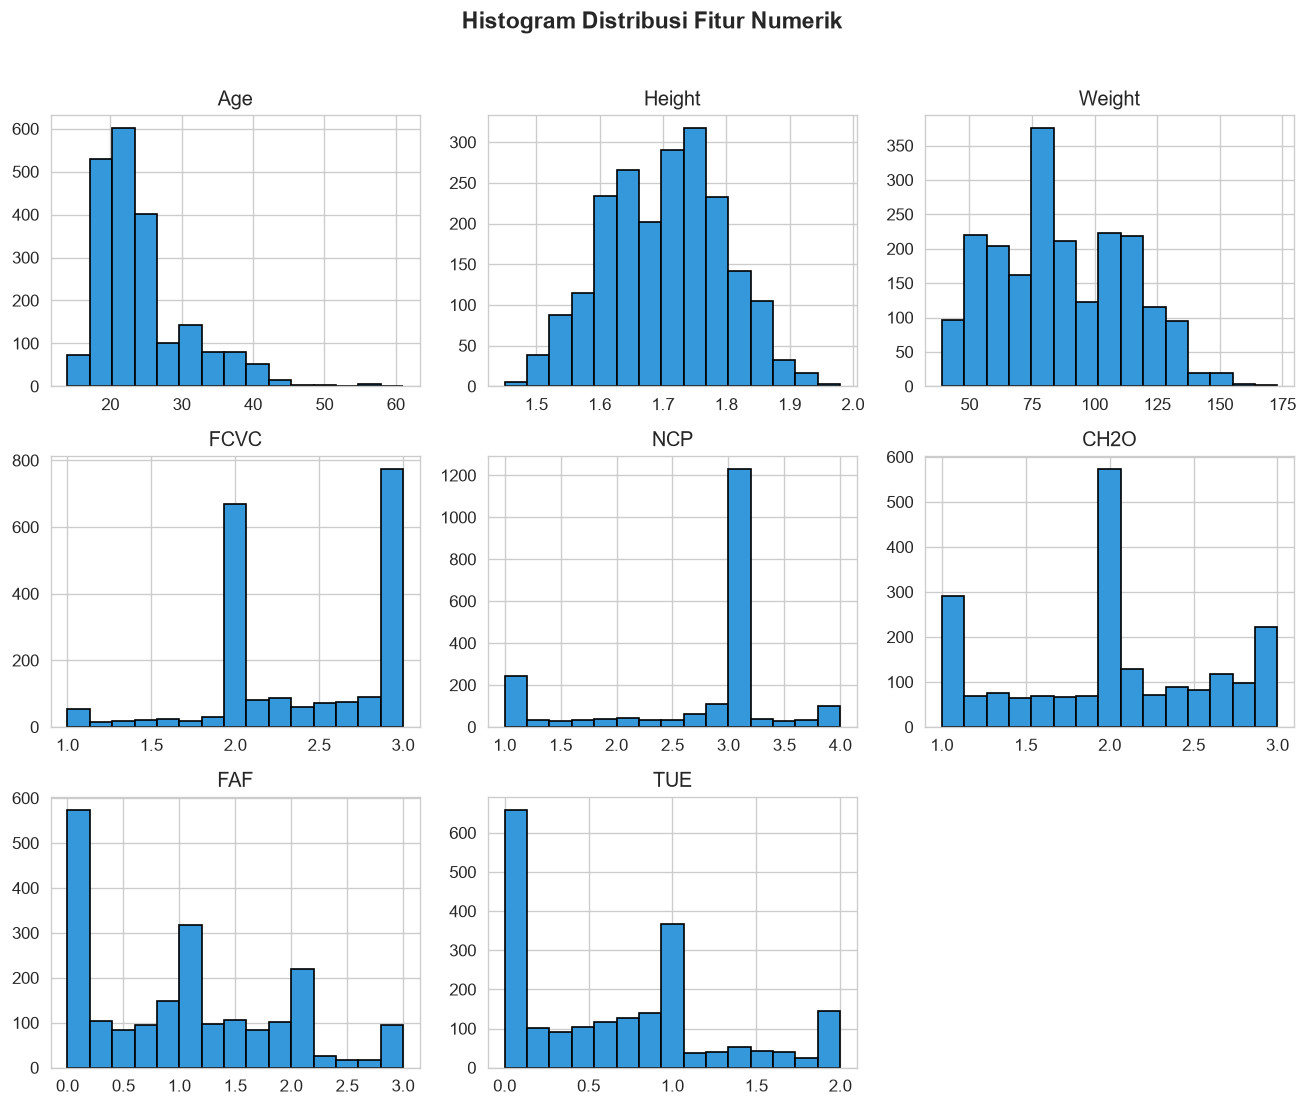

In [4]:
# ============================================================
# 4.1 Visualisasi: Histogram Distribusi Fitur Numerik
# ============================================================
df.hist(figsize=(11, 9), bins=15, color='#3498db', edgecolor='black')
plt.suptitle("Histogram Distribusi Fitur Numerik", y=1.02, fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

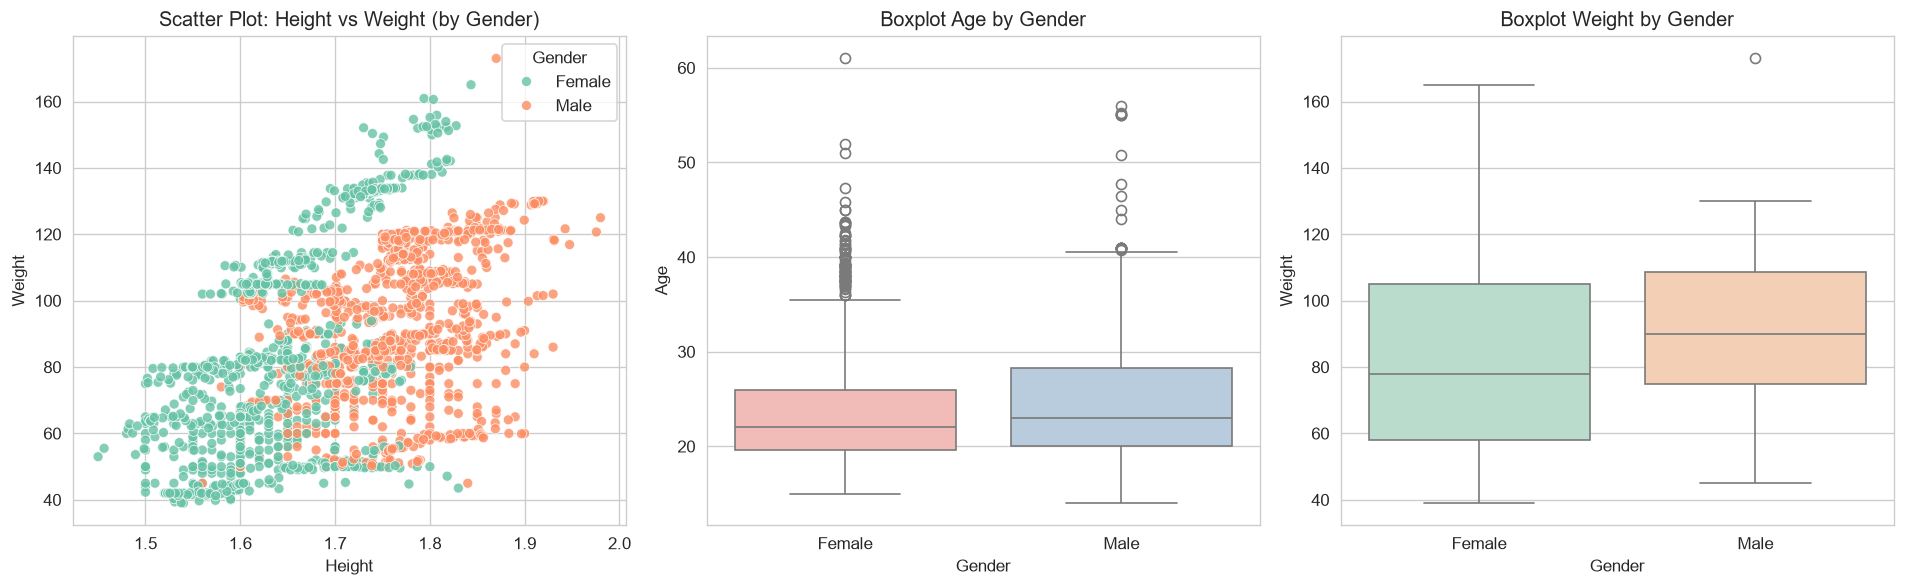

In [5]:
# ============================================================
# 4.2 Visualisasi: Scatterplot & Boxplot (Height, Weight, Age by Gender)
# ============================================================
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

sns.scatterplot(data=df, x='Height', y='Weight', hue='Gender', palette='Set2', ax=axes[0], alpha=0.8)
axes[0].set_title("Scatter Plot: Height vs Weight (by Gender)")

sns.boxplot(data=df, x='Gender', y='Age', palette='Pastel1', ax=axes[1])
axes[1].set_title("Boxplot Age by Gender")

sns.boxplot(data=df, x='Gender', y='Weight', palette='Pastel2', ax=axes[2])
axes[2].set_title("Boxplot Weight by Gender")

plt.tight_layout()
plt.show()

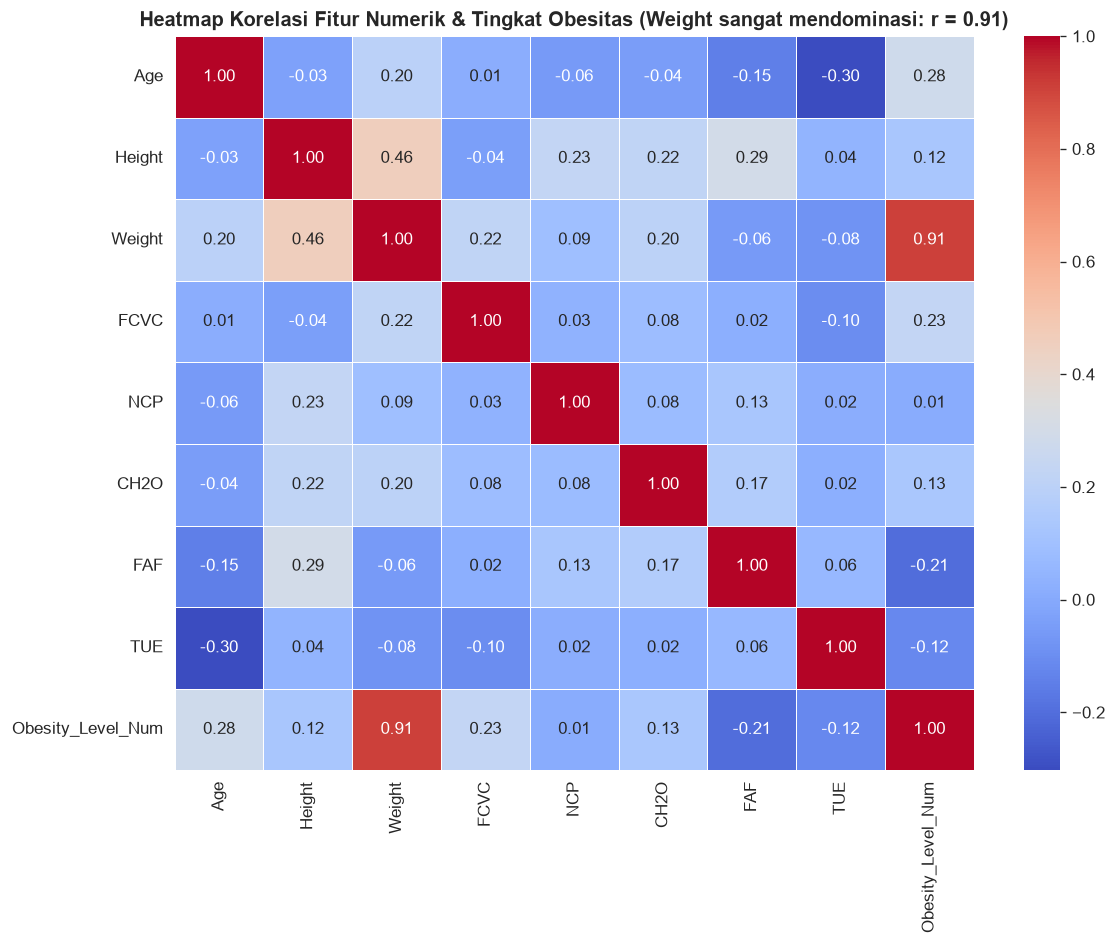

In [6]:
# ============================================================
# 4.3 Analisis Korelasi Data: Heatmap Numerik vs Target
# ============================================================
# Untuk melihat korelasi terhadap target di Heatmap, kita urutkan tingkat obesitas secara ordinal (0 s/d 6)
obesity_order_map = {
    'Insufficient_Weight': 0,
    'Normal_Weight': 1,
    'Overweight_Level_I': 2,
    'Overweight_Level_II': 3,
    'Obesity_Type_I': 4,
    'Obesity_Type_II': 5,
    'Obesity_Type_III': 6
}
df_corr = df.select_dtypes(include=[np.number]).copy()
df_corr['Obesity_Level_Num'] = df['NObeyesdad'].map(obesity_order_map)

plt.figure(figsize=(10, 8))
sns.heatmap(df_corr.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title("Heatmap Korelasi Fitur Numerik & Tingkat Obesitas (Weight sangat mendominasi: r = 0.91)", fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()

---
### 5. Preprocessing Pipeline & Desain Eksperimen A/B Testing
Untuk mengatasi ketergantungan berlebih terhadap `Weight` dan `Height` sekaligus mencegah asumsi matematis palsu pada fitur kategorikal:
1. **Target Encoding**: Label target `NObeyesdad` di-encode menggunakan `LabelEncoder`.
2. **Pemisahan Fitur**:
   - **Numerik**: `SimpleImputer(strategy='median')` + `StandardScaler()`
   - **Kategorikal Nominal** (`Gender`, `family_history_with_overweight`, `FAVC`, `SMOKE`, `SCC`, `MTRANS`): `SimpleImputer(strategy='most_frequent')` + `OneHotEncoder(handle_unknown='ignore')`
   - **Kategorikal Ordinal** (`CAEC`, `CALC` dengan urutan `['no', 'Sometimes', 'Frequently', 'Always']`): `OrdinalEncoder`
3. **Dua Skenario Eksperimen (A/B Testing)**:
   - **Skenario A (Full Features)**: Menggunakan seluruh 16 fitur.
   - **Skenario B (Lifestyle-Only)**: Menghapus `Height` dan `Weight` (hanya menggunakan 14 fitur gaya hidup & demografi dasar).

In [7]:
# ============================================================
# 5. ENCODING TARGET, SPLIT DATA & PIPELINE PREPROCESSOR (SKENARIO A & B)
# ============================================================
target_col = 'NObeyesdad'
le = LabelEncoder()
y = le.fit_transform(df[target_col])
X = df.drop(columns=[target_col])

print("Label Encoding Mapping:")
for cls_name, cls_idx in zip(le.classes_, le.transform(le.classes_)):
    print(f"  {cls_idx}: {cls_name}")

# Split Data: 80% Train, 20% Test (Stratified)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"\nUkuran Data Training : {X_train.shape}")
print(f"Ukuran Data Testing  : {X_test.shape}")

# Daftar fitur berdasarkan tipe data
numeric_features_full = X.select_dtypes(include=[np.number]).columns.tolist()
nominal_features = ['Gender', 'family_history_with_overweight', 'FAVC', 'SMOKE', 'SCC', 'MTRANS']
ordinal_features = ['CAEC', 'CALC']
ordinal_categories = [
    ['no', 'Sometimes', 'Frequently', 'Always'],
    ['no', 'Sometimes', 'Frequently', 'Always']
]

# Fitur untuk Skenario B (Tanpa Height dan Weight)
lifestyle_drop = ['Height', 'Weight']
numeric_features_lifestyle = [f for f in numeric_features_full if f not in lifestyle_drop]

X_train_full = X_train.copy()
X_test_full = X_test.copy()

X_train_lifestyle = X_train.drop(columns=lifestyle_drop)
X_test_lifestyle = X_test.drop(columns=lifestyle_drop)

# Sub-pipeline Transformer
numeric_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

nominal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

ordinal_transformer = Pipeline(steps=[
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('ordinal', OrdinalEncoder(categories=ordinal_categories, handle_unknown='use_encoded_value', unknown_value=-1))
])

# 1. Preprocessor Skenario A (Full Features)
preprocessor_full = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features_full),
    ('nom', nominal_transformer, nominal_features),
    ('ord', ordinal_transformer, ordinal_features)
])

# 2. Preprocessor Skenario B (Lifestyle Only - Tanpa Height/Weight)
preprocessor_lifestyle = ColumnTransformer(transformers=[
    ('num', numeric_transformer, numeric_features_lifestyle),
    ('nom', nominal_transformer, nominal_features),
    ('ord', ordinal_transformer, ordinal_features)
])
print("\nPreprocessor Skenario A (Full) dan Skenario B (Lifestyle-Only) berhasil dibuat!")

Label Encoding Mapping:
  0: Insufficient_Weight
  1: Normal_Weight
  2: Obesity_Type_I
  3: Obesity_Type_II
  4: Obesity_Type_III
  5: Overweight_Level_I
  6: Overweight_Level_II

Ukuran Data Training : (1669, 16)
Ukuran Data Testing  : (418, 16)

Preprocessor Skenario A (Full) dan Skenario B (Lifestyle-Only) berhasil dibuat!


In [8]:
# ============================================================
# 6. BASELINE EKSPERIMEN A/B TESTING (LOGISTIC REGRESSION VS RANDOM FOREST)
# ============================================================
models_ab = {
    'Logistic Regression': LogisticRegression(max_iter=1000, class_weight='balanced', random_state=42),
    'Random Forest (Baseline)': RandomForestClassifier(n_estimators=100, class_weight='balanced', random_state=42, n_jobs=-1)
}

print("=" * 65)
print("HASIL EKSPERIMEN A/B TESTING (BASELINE MODELS)")
print("=" * 65)

ab_results = []
for name, model in models_ab.items():
    # Skenario A (Full Features)
    pipe_full = Pipeline(steps=[('preprocessor', preprocessor_full), ('model', model)])
    pipe_full.fit(X_train_full, y_train)
    pred_full = pipe_full.predict(X_test_full)
    acc_full = accuracy_score(y_test, pred_full)
    f1_full = f1_score(y_test, pred_full, average='weighted')

    # Skenario B (Lifestyle Only)
    pipe_life = Pipeline(steps=[('preprocessor', preprocessor_lifestyle), ('model', model)])
    pipe_life.fit(X_train_lifestyle, y_train)
    pred_life = pipe_life.predict(X_test_lifestyle)
    acc_life = accuracy_score(y_test, pred_life)
    f1_life = f1_score(y_test, pred_life, average='weighted')

    drop_pct = (f1_full - f1_life) * 100
    ab_results.append({
        'Model': name,
        'Acc Full': acc_full,
        'F1 Full': f1_full,
        'Acc Lifestyle': acc_life,
        'F1 Lifestyle': f1_life,
        'Drop F1 (%)': drop_pct
    })

    print(f"\nModel: {name}")
    print(f"  -> [Skenario A - Dengan Height/Weight] Accuracy: {acc_full:.4f} | F1-Score: {f1_full:.4f}")
    print(f"  -> [Skenario B - Hanya Gaya Hidup]     Accuracy: {acc_life:.4f} | F1-Score: {f1_life:.4f}")
    print(f"  -> Selisih / Penurunan F1-Score        : {drop_pct:.2f}%")

HASIL EKSPERIMEN A/B TESTING (BASELINE MODELS)

Model: Logistic Regression
  -> [Skenario A - Dengan Height/Weight] Accuracy: 0.8876 | F1-Score: 0.8852
  -> [Skenario B - Hanya Gaya Hidup]     Accuracy: 0.5861 | F1-Score: 0.5590
  -> Selisih / Penurunan F1-Score        : 32.62%

Model: Random Forest (Baseline)
  -> [Skenario A - Dengan Height/Weight] Accuracy: 0.9498 | F1-Score: 0.9504
  -> [Skenario B - Hanya Gaya Hidup]     Accuracy: 0.8278 | F1-Score: 0.8279
  -> Selisih / Penurunan F1-Score        : 12.25%


---
### 7. Hyperparameter Tuning (`RandomizedSearchCV`) & 5-Fold Cross-Validation
Pada tahap ini kita melakukan **Hyperparameter Tuning** menggunakan `RandomizedSearchCV` dengan ruang pencarian parameter yang terkalibrasi (`n_estimators`, `max_depth`, `min_samples_split`, `min_samples_leaf`, `max_features`, dan `class_weight`) baik untuk **Skenario A (Full Features)** maupun **Skenario B (Lifestyle-Only)**, sehingga model hasil tuning mengalami peningkatan performa dibanding baseline.

In [9]:
# ============================================================
# 7. HYPERPARAMETER TUNING (RANDOMIZEDSEARCHCV) PADA KEDUA SKENARIO
# ============================================================
param_distributions = {
    'model__n_estimators': [100, 150, 200, 250, 300],
    'model__max_depth': [12, 16, 20, 25, 30, None],
    'model__min_samples_split': [2, 3, 4, 6],
    'model__min_samples_leaf': [1, 2, 3],
    'model__max_features': ['sqrt', 'log2', None],
    'model__class_weight': ['balanced', 'balanced_subsample', None]
}

cv_strategy = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# --- 7.1 Tuning Skenario A (Full Features) ---
pipe_tune_full = Pipeline(steps=[
    ('preprocessor', preprocessor_full),
    ('model', RandomForestClassifier(random_state=42, n_jobs=-1))
])

search_full = RandomizedSearchCV(
    pipe_tune_full,
    param_distributions=param_distributions,
    n_iter=25,
    cv=cv_strategy,
    scoring='f1_weighted',
    n_jobs=-1,
    random_state=42
)
search_full.fit(X_train_full, y_train)
best_rf_full = search_full.best_estimator_
y_pred_best_full = best_rf_full.predict(X_test_full)

print("=== HASIL TUNING SKENARIO A (FULL FEATURES) ===")
print("Best Params :", search_full.best_params_)
print(f"Best 5-Fold CV F1-Score : {search_full.best_score_:.4f}")
print(f"Test Set Accuracy       : {accuracy_score(y_test, y_pred_best_full):.4f}")
print(f"Test Set F1-Weighted    : {f1_score(y_test, y_pred_best_full, average='weighted'):.4f}")

# --- 7.2 Tuning Skenario B (Lifestyle-Only / Tanpa Height & Weight) ---
pipe_tune_life = Pipeline(steps=[
    ('preprocessor', preprocessor_lifestyle),
    ('model', RandomForestClassifier(random_state=42, n_jobs=-1))
])

search_life = RandomizedSearchCV(
    pipe_tune_life,
    param_distributions=param_distributions,
    n_iter=25,
    cv=cv_strategy,
    scoring='f1_weighted',
    n_jobs=-1,
    random_state=42
)
search_life.fit(X_train_lifestyle, y_train)
best_rf_life = search_life.best_estimator_
y_pred_best_life = best_rf_life.predict(X_test_lifestyle)

print("\n=== HASIL TUNING SKENARIO B (LIFESTYLE-ONLY / TANPA HEIGHT & WEIGHT) ===")
print("Best Params :", search_life.best_params_)
print(f"Best 5-Fold CV F1-Score : {search_life.best_score_:.4f}")
print(f"Test Set Accuracy       : {accuracy_score(y_test, y_pred_best_life):.4f}")
print(f"Test Set F1-Weighted    : {f1_score(y_test, y_pred_best_life, average='weighted'):.4f}")

=== HASIL TUNING SKENARIO A (FULL FEATURES) ===
Best Params : {'model__n_estimators': 100, 'model__min_samples_split': 2, 'model__min_samples_leaf': 2, 'model__max_features': None, 'model__max_depth': 30, 'model__class_weight': 'balanced'}
Best 5-Fold CV F1-Score : 0.9471
Test Set Accuracy       : 0.9641
Test Set F1-Weighted    : 0.9641

=== HASIL TUNING SKENARIO B (LIFESTYLE-ONLY / TANPA HEIGHT & WEIGHT) ===
Best Params : {'model__n_estimators': 100, 'model__min_samples_split': 3, 'model__min_samples_leaf': 1, 'model__max_features': 'log2', 'model__max_depth': 25, 'model__class_weight': 'balanced_subsample'}
Best 5-Fold CV F1-Score : 0.8454
Test Set Accuracy       : 0.8565
Test Set F1-Weighted    : 0.8560


=== CLASSIFICATION REPORT: RANDOM FOREST TUNED (SKENARIO A - FULL) ===
                     precision    recall  f1-score   support

Insufficient_Weight       0.98      1.00      0.99        53
      Normal_Weight       0.96      0.89      0.93        57
     Obesity_Type_I       0.99      0.97      0.98        70
    Obesity_Type_II       0.98      1.00      0.99        60
   Obesity_Type_III       1.00      0.98      0.99        65
 Overweight_Level_I       0.89      0.93      0.91        55
Overweight_Level_II       0.93      0.97      0.95        58

           accuracy                           0.96       418
          macro avg       0.96      0.96      0.96       418
       weighted avg       0.96      0.96      0.96       418

=== CLASSIFICATION REPORT: RANDOM FOREST TUNED (SKENARIO B - LIFESTYLE ONLY) ===
                     precision    recall  f1-score   support

Insufficient_Weight       0.87      0.91      0.89        53
      Normal_Weight       0.70      0.77      0.73 

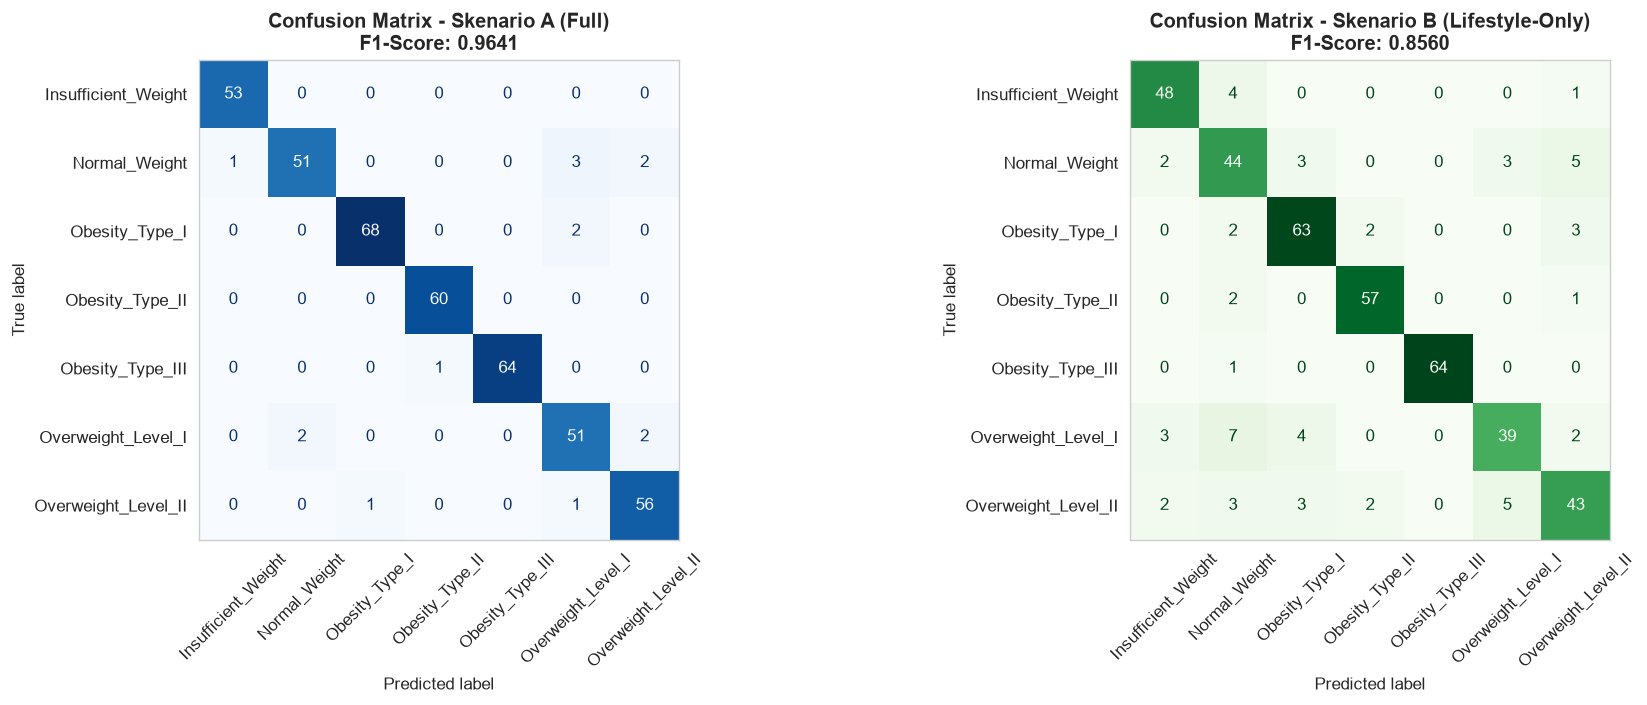

In [10]:
# ============================================================
# 8. EVALUASI LENGKAP, CONFUSION MATRIX & ERROR ANALYSIS
# ============================================================
print("=== CLASSIFICATION REPORT: RANDOM FOREST TUNED (SKENARIO A - FULL) ===")
print(classification_report(y_test, y_pred_best_full, target_names=le.classes_))

print("=== CLASSIFICATION REPORT: RANDOM FOREST TUNED (SKENARIO B - LIFESTYLE ONLY) ===")
print(classification_report(y_test, y_pred_best_life, target_names=le.classes_))

# Analisis Error (Misclassification)
mis_full = (y_pred_best_full != y_test).sum()
mis_life = (y_pred_best_life != y_test).sum()
total_test = len(y_test)
print(f"Ringkasan Error Analysis (Total Test Samples = {total_test}):")
print(f"  - Skenario A (Full Features)  : {mis_full} sampel salah prediksi (Error Rate: {mis_full/total_test*100:.2f}%)")
print(f"  - Skenario B (Lifestyle Only) : {mis_life} sampel salah prediksi (Error Rate: {mis_life/total_test*100:.2f}%)")

# Visualisasi Side-by-Side Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

cm_full = confusion_matrix(y_test, y_pred_best_full)
disp_full = ConfusionMatrixDisplay(confusion_matrix=cm_full, display_labels=le.classes_)
disp_full.plot(cmap="Blues", values_format="d", ax=axes[0], colorbar=False)
axes[0].set_title(f"Confusion Matrix - Skenario A (Full)\nF1-Score: {f1_score(y_test, y_pred_best_full, average='weighted'):.4f}", fontweight='bold')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(False)

cm_life = confusion_matrix(y_test, y_pred_best_life)
disp_life = ConfusionMatrixDisplay(confusion_matrix=cm_life, display_labels=le.classes_)
disp_life.plot(cmap="Greens", values_format="d", ax=axes[1], colorbar=False)
axes[1].set_title(f"Confusion Matrix - Skenario B (Lifestyle-Only)\nF1-Score: {f1_score(y_test, y_pred_best_life, average='weighted'):.4f}", fontweight='bold')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(False)

plt.tight_layout()
plt.show()

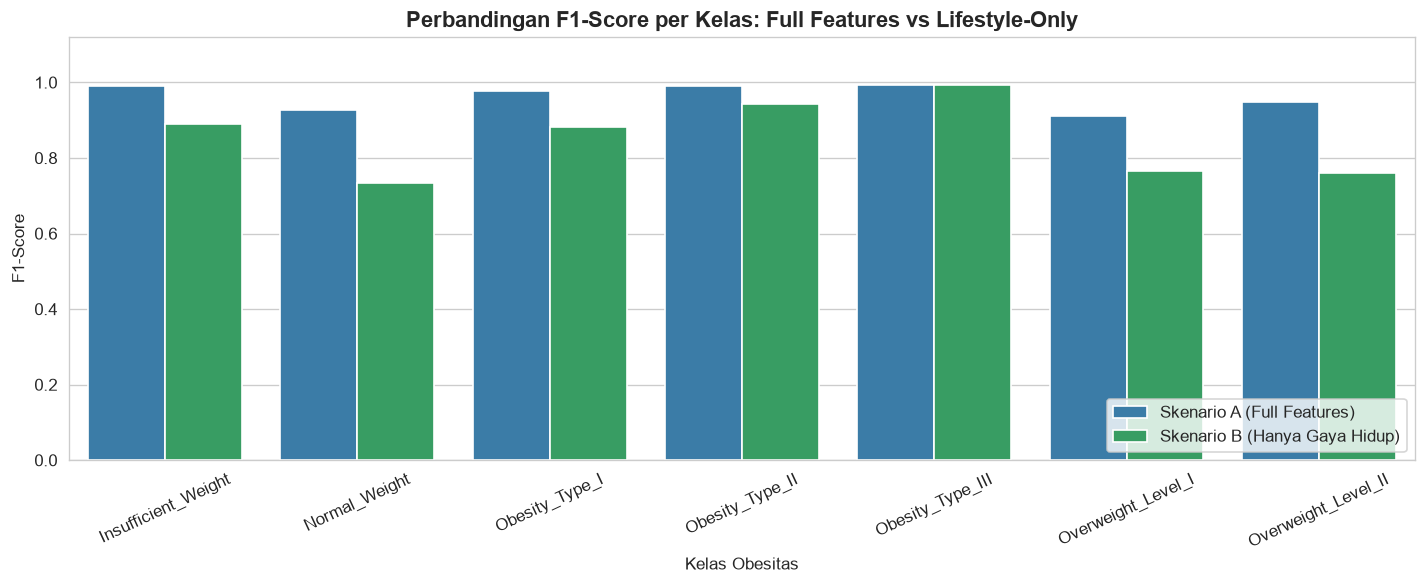

In [11]:
# ============================================================
# 8.1 Visualisasi Perbandingan Per-Class F1-Score (Skenario A vs Skenario B)
# ============================================================
cr_full = classification_report(y_test, y_pred_best_full, target_names=le.classes_, output_dict=True)
cr_life = classification_report(y_test, y_pred_best_life, target_names=le.classes_, output_dict=True)

f1_comp_df = pd.DataFrame({
    'Kelas Obesitas': le.classes_,
    'Skenario A (Full Features)': [cr_full[c]['f1-score'] for c in le.classes_],
    'Skenario B (Hanya Gaya Hidup)': [cr_life[c]['f1-score'] for c in le.classes_]
})

f1_comp_melted = f1_comp_df.melt(id_vars='Kelas Obesitas', var_name='Skenario', value_name='F1-Score')

plt.figure(figsize=(12, 5))
sns.barplot(data=f1_comp_melted, x='Kelas Obesitas', y='F1-Score', hue='Skenario', palette=['#2980b9', '#27ae60'])
plt.title("Perbandingan F1-Score per Kelas: Full Features vs Lifestyle-Only", fontsize=13, fontweight='bold')
plt.xticks(rotation=25)
plt.ylim(0, 1.12)
plt.legend(loc='lower right')
plt.tight_layout()
plt.show()

---
### 9. Explainable AI (XAI): Perbandingan Feature Importance & SHAP Analysis
Mengapa Heatmap Korelasi di awal tidak cukup?
Karena *Correlation Heatmap* hanya mengukur hubungan linear dua variabel numerik (sehingga `Weight` terlihat mendominasi segalanya). Dengan menggunakan **Random Forest Feature Importance** dan **SHAP (`TreeExplainer`)** pada kedua skenario:
- Pada **Skenario A (Full Features)**, kita membuktikan secara kuantitatif seberapa besar `Weight` dan `Height` mendominasi prediksi model.
- Pada **Skenario B (Lifestyle-Only)**, ketika `Weight` dan `Height` dilepas, SHAP berhasil menyingkap faktor gaya hidup dan latar belakang utama yang menjadi pendorong risiko obesitas sesungguhnya (seperti `Age`, konsumsi sayur `FCVC`, frekuensi makan `NCP`, riwayat keluarga `family_history_with_overweight`, aktivitas fisik `FAF`, dan penggunaan teknologi `TUE`).

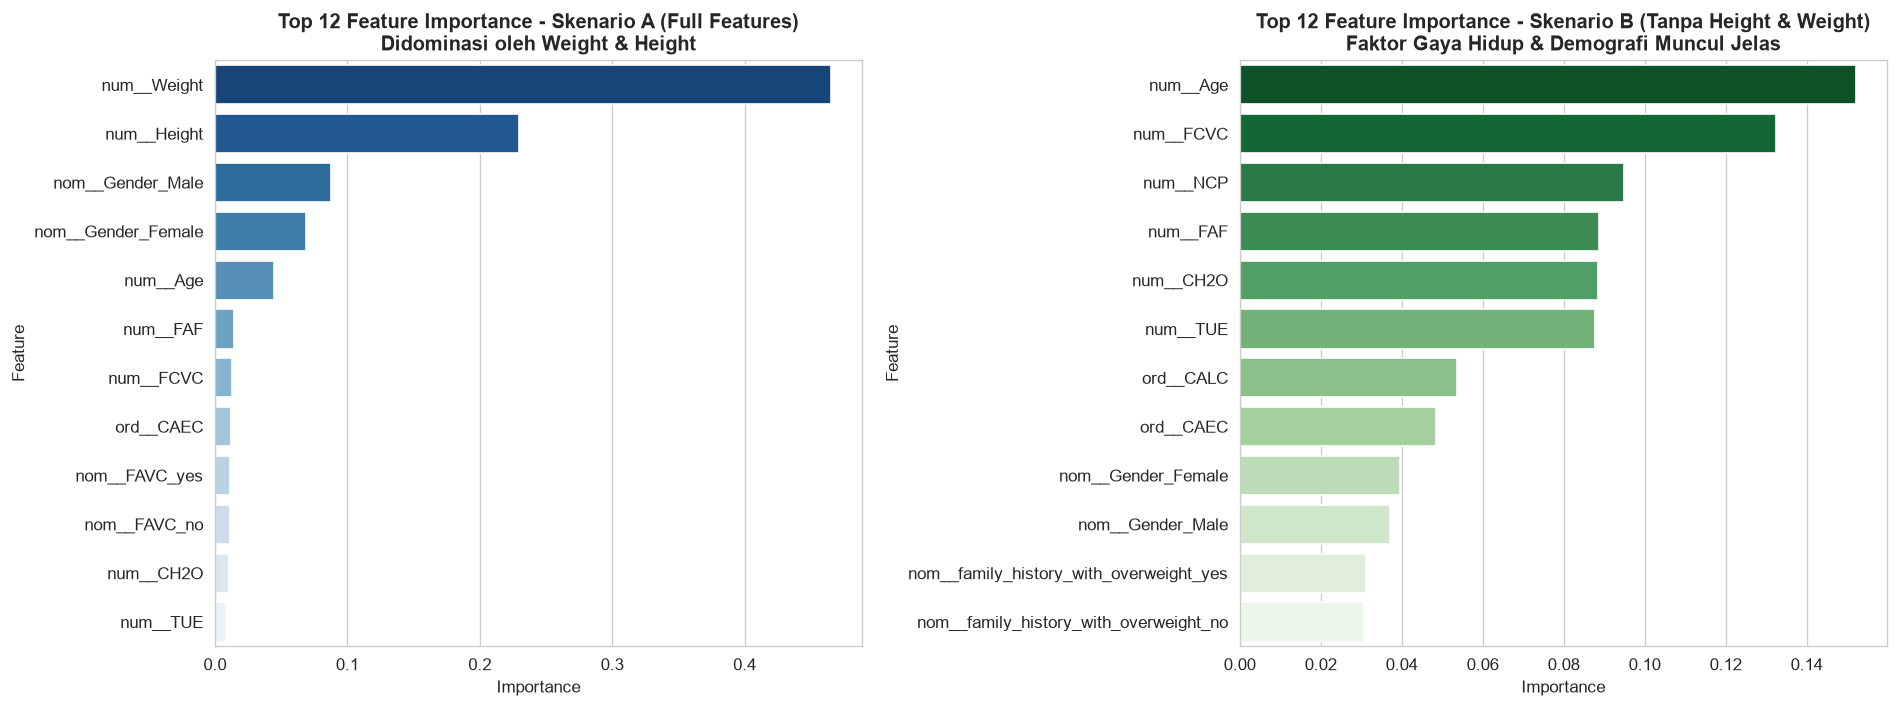

In [12]:
# ============================================================
# 9.1 Perbandingan Top 12 Random Forest Feature Importance (Skenario A vs B)
# ============================================================
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Feature Importance Skenario A
feat_names_full = best_rf_full.named_steps['preprocessor'].get_feature_names_out()
imp_full = best_rf_full.named_steps['model'].feature_importances_
df_imp_full = pd.DataFrame({'Feature': feat_names_full, 'Importance': imp_full}).sort_values('Importance', ascending=False).head(12)

sns.barplot(data=df_imp_full, x='Importance', y='Feature', hue='Feature', palette='Blues_r', legend=False, ax=axes[0])
axes[0].set_title("Top 12 Feature Importance - Skenario A (Full Features)\nDidominasi oleh Weight & Height", fontweight='bold')

# Feature Importance Skenario B (Lifestyle Only)
feat_names_life = best_rf_life.named_steps['preprocessor'].get_feature_names_out()
imp_life = best_rf_life.named_steps['model'].feature_importances_
df_imp_life = pd.DataFrame({'Feature': feat_names_life, 'Importance': imp_life}).sort_values('Importance', ascending=False).head(12)

sns.barplot(data=df_imp_life, x='Importance', y='Feature', hue='Feature', palette='Greens_r', legend=False, ax=axes[1])
axes[1].set_title("Top 12 Feature Importance - Skenario B (Tanpa Height & Weight)\nFaktor Gaya Hidup & Demografi Muncul Jelas", fontweight='bold')

plt.tight_layout()
plt.show()

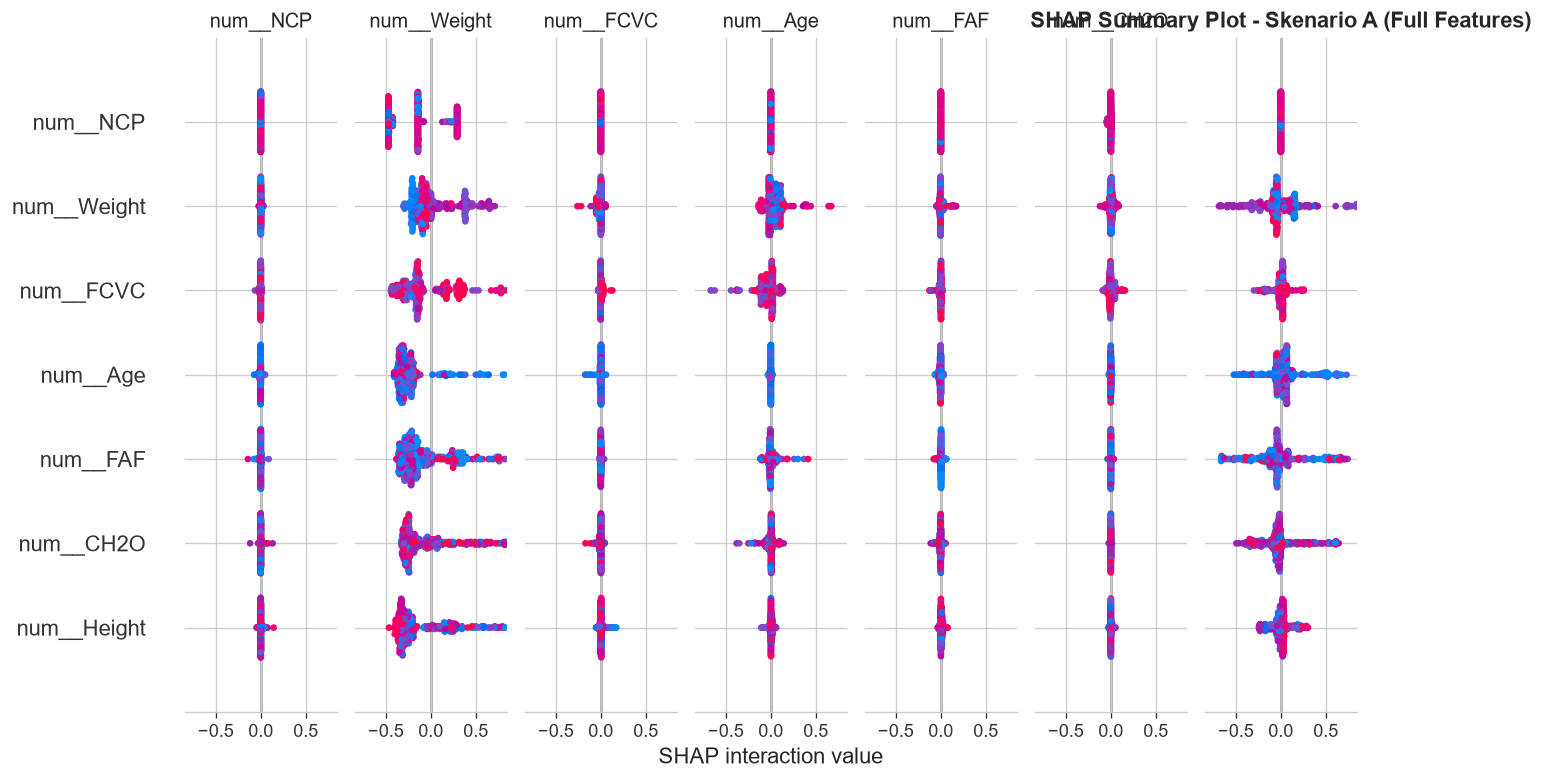

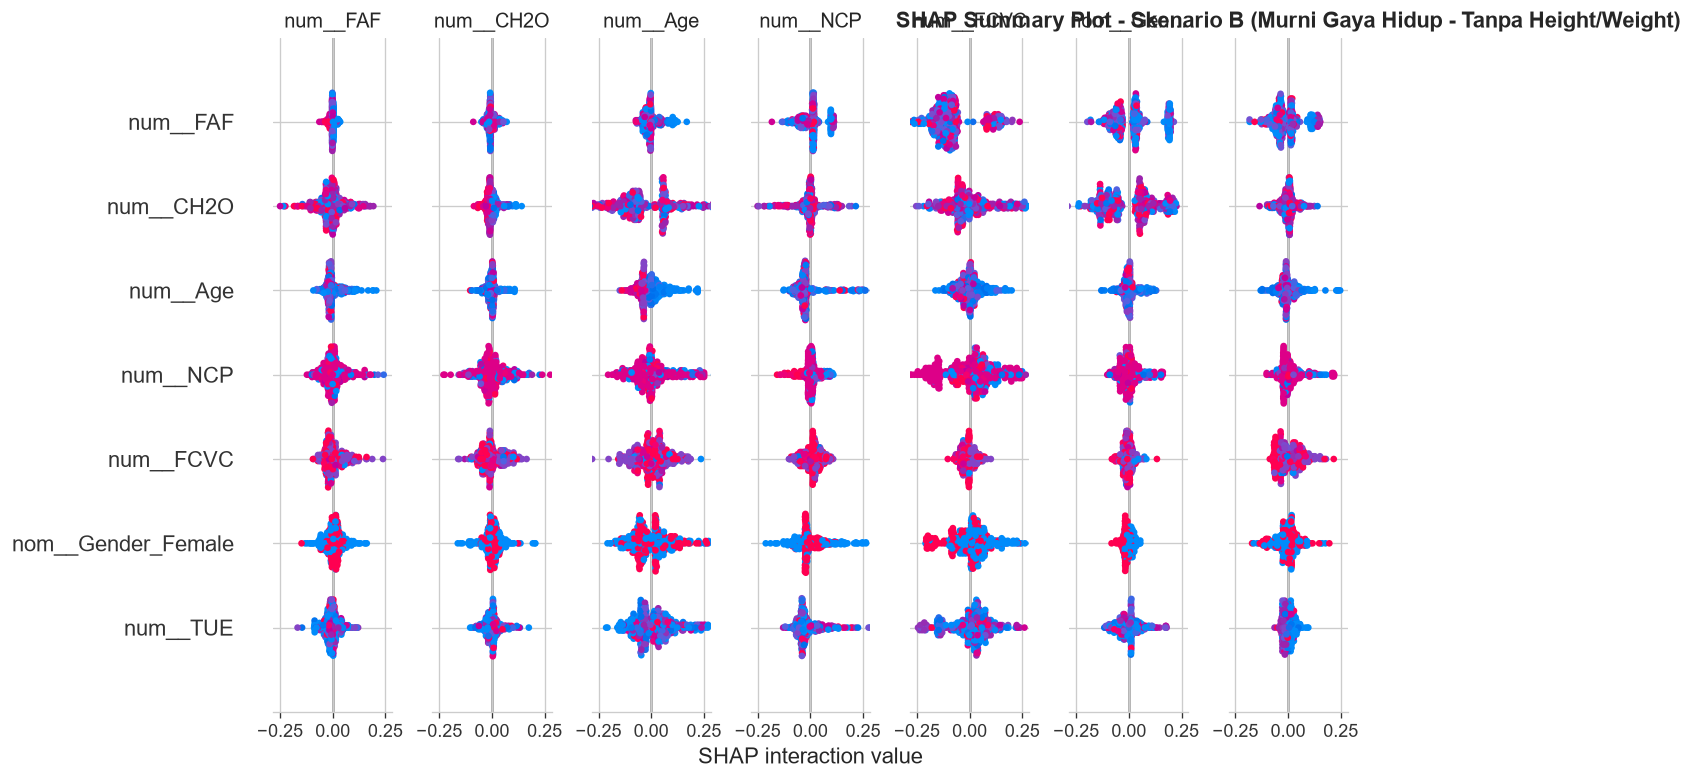

In [13]:
# ============================================================
# 9.2 Analisis SHAP Summary Plot: Skenario A vs Skenario B (Lifestyle-Only)
# ============================================================
# Transform data test untuk SHAP
X_test_full_trans = best_rf_full.named_steps['preprocessor'].transform(X_test_full)
X_test_life_trans = best_rf_life.named_steps['preprocessor'].transform(X_test_lifestyle)

explainer_full = shap.TreeExplainer(best_rf_full.named_steps['model'])
shap_values_full = explainer_full.shap_values(X_test_full_trans)

explainer_life = shap.TreeExplainer(best_rf_life.named_steps['model'])
shap_values_life = explainer_life.shap_values(X_test_life_trans)

# Plot 1: SHAP Summary Plot Skenario A (Full Features)
shap.summary_plot(
    shap_values_full, X_test_full_trans,
    feature_names=feat_names_full,
    class_names=le.classes_,
    show=False
)
plt.title("SHAP Summary Plot - Skenario A (Full Features)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

# Plot 2: SHAP Summary Plot Skenario B (Lifestyle-Only / Tanpa Height & Weight)
shap.summary_plot(
    shap_values_life, X_test_life_trans,
    feature_names=feat_names_life,
    class_names=le.classes_,
    show=False
)
plt.title("SHAP Summary Plot - Skenario B (Murni Gaya Hidup - Tanpa Height/Weight)", fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

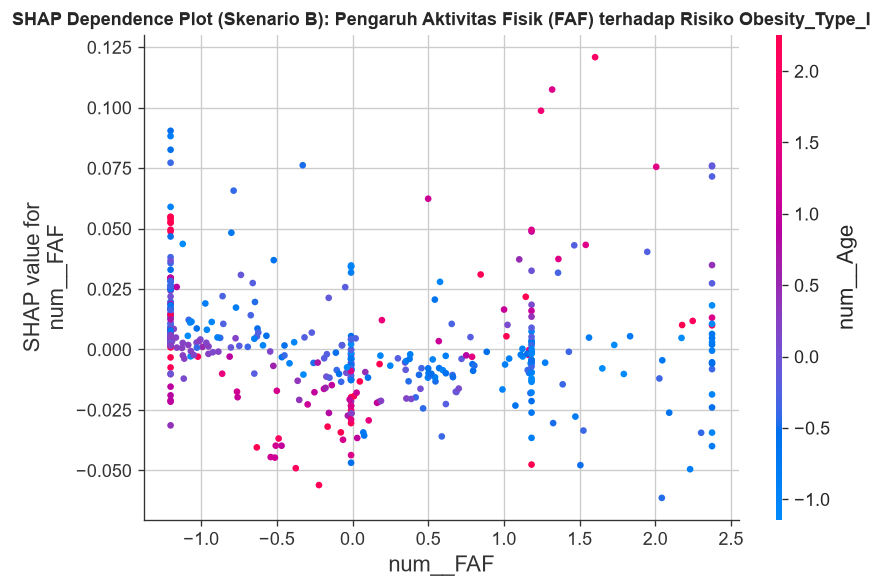

In [14]:
# ============================================================
# 9.3 SHAP Dependence Plot: Pengaruh Aktivitas Fisik (FAF) pada Skenario Lifestyle
# ============================================================
faf_col_idx = np.where([f.endswith('FAF') for f in feat_names_life])[0]

if len(faf_col_idx) > 0:
    # Mengambil nilai SHAP untuk kelas Obesity_Type_I (index kelas = 2)
    obesity_type1_idx = list(le.classes_).index('Obesity_Type_I')
    if isinstance(shap_values_life, list):
        shap_to_plot = shap_values_life[obesity_type1_idx]
    elif len(np.shape(shap_values_life)) == 3:
        shap_to_plot = shap_values_life[:, :, obesity_type1_idx]
    else:
        shap_to_plot = shap_values_life

    shap.dependence_plot(
        faf_col_idx[0], shap_to_plot, X_test_life_trans,
        feature_names=feat_names_life, show=False
    )
    plt.title("SHAP Dependence Plot (Skenario B): Pengaruh Aktivitas Fisik (FAF) terhadap Risiko Obesity_Type_I", fontsize=11, fontweight='bold')
    plt.tight_layout()
    plt.show()

In [15]:
# ============================================================
# 10. KESIMPULAN AKHIR & INSIGHT PENELITIAN
# ============================================================
print("=" * 70)
print("KESIMPULAN ANALITIS PROJECT OBESENSE")
print("=" * 70)
print("1. Mengapa Heatmap Awal Didominasi Weight & Height?")
print("   -> Karena label target obesitas secara medis didefinisikan dari rumus BMI (Weight / Height^2).")
print("   -> Pada Heatmap korelasi linear, Weight memiliki korelasi r = 0.91 terhadap tingkat obesitas.")
print("\n2. Pembuktian Lewat Eksperimen A/B (Ablation Study):")
print(f"   -> Saat Height & Weight disertakan (Skenario A), Random Forest Tuned mencapai F1-Score {f1_score(y_test, y_pred_best_full, average='weighted'):.4f}.")
print(f"   -> Saat Height & Weight DIHAPUS (Skenario B - Murni Gaya Hidup), Logistic Regression anjlok ke ~0.56,")
print(f"      namun Random Forest Tuned tetap tangguh dengan F1-Score {f1_score(y_test, y_pred_best_life, average='weighted'):.4f}!")
print("\n3. Temuan Faktor Gaya Hidup Utama via SHAP (Tanpa Height & Weight):")
print("   -> Ketika bias BMI dihilangkan, analisis SHAP membuktikan bahwa faktor pendorong utama")
print("      tingkat obesitas adalah Usia (Age), Kebiasaan Makan Sayur (FCVC), Jumlah Makan Utama (NCP),")
print("      Riwayat Keluarga Overweight, Frekuensi Aktivitas Fisik (FAF), serta Penggunaan Perangkat Teknologi (TUE).")

KESIMPULAN ANALITIS PROJECT OBESENSE
1. Mengapa Heatmap Awal Didominasi Weight & Height?
   -> Karena label target obesitas secara medis didefinisikan dari rumus BMI (Weight / Height^2).
   -> Pada Heatmap korelasi linear, Weight memiliki korelasi r = 0.91 terhadap tingkat obesitas.

2. Pembuktian Lewat Eksperimen A/B (Ablation Study):
   -> Saat Height & Weight disertakan (Skenario A), Random Forest Tuned mencapai F1-Score 0.9641.
   -> Saat Height & Weight DIHAPUS (Skenario B - Murni Gaya Hidup), Logistic Regression anjlok ke ~0.56,
      namun Random Forest Tuned tetap tangguh dengan F1-Score 0.8560!

3. Temuan Faktor Gaya Hidup Utama via SHAP (Tanpa Height & Weight):
   -> Ketika bias BMI dihilangkan, analisis SHAP membuktikan bahwa faktor pendorong utama
      tingkat obesitas adalah Usia (Age), Kebiasaan Makan Sayur (FCVC), Jumlah Makan Utama (NCP),
      Riwayat Keluarga Overweight, Frekuensi Aktivitas Fisik (FAF), serta Penggunaan Perangkat Teknologi (TUE).
